# *Concept drift* de clientes no SynCCFD

Este notebook mostra o *concept drift* de clientes do SynCCFD (Fase 2 do plano
`docs/plan-v0.2.md`). Cada cliente tem um **regime A** (o perfil original); um cliente
com *drift* ganha também um **regime B**, sorteado a partir de A, e um tipo de *drift*
que define o peso de B ao longo do tempo, $w(t) \in [0, 1]$:

| tipo | $w(t)$ | como se aplica |
|---|---|---|
| súbito | 0 antes de $t_0$, 1 depois | parâmetros de B a partir de $t_0$ |
| gradual | sobe de 0 a 1 em $[t_0, t_0 + L]$ | cada transação vem de B com probabilidade $w(t)$ |
| incremental | idem | parâmetros interpolados: $\theta(t) = (1 - w)\,\theta_A + w\,\theta_B$ |
| recorrente | 1 durante $D$ dias a cada $P$ dias, a partir de $t_0$ | ex.: férias, viagens |

As figuras são gravadas em PDF em `docs/figures/fase2/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from synccfd import DatasetGenerator
from synccfd.simulator import presets
from synccfd.simulator.config import MerchantConfig
from synccfd.simulator.engine.drift import CustomerDrift, regime_weight

# Where the figures are saved (the tests point this to a temporary folder)
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "../docs/figures/fase2"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette (see the dataviz notes in the PR): fixed order
COLOR_A, COLOR_B = "#2a78d6", "#eb6834"
TYPE_COLORS = {"sudden": "#2a78d6", "gradual": "#eb6834", "incremental": "#1baf7a", "recurrent": "#eda100"}
TYPE_NAMES = {"sudden": "súbito", "gradual": "gradual", "incremental": "incremental", "recurrent": "recorrente"}
MUTED, INK = "#8a8985", "#0b0b0b"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

## Geração

O conjunto de dados é o da configuração final da dissertação ("Fechamento do [SIM]" em
`docs/plan-v0.2.md`): `presets.realistic()`, com comerciantes, *drift* (30% dos
clientes, padrão do `DriftConfig`), sazonalidade e fraudes injetadas. As figuras usam só
as transações legítimas: com a injeção, as fraudes são compras novas, e as legítimas
continuam todas no conjunto, com o regime de origem em `GT_REGIME`.

Com comerciantes, o valor de uma compra vem da categoria e do **fator de gasto** do
cliente; a mudança de valor entre A e B é a razão entre os fatores de gasto de B e de A
(`GT_B_spending_factor / spending_factor`). Sem comerciantes, é a razão entre os
valores médios (`GT_B_mean_amount / mean_amount`).

In [2]:
# The final configuration; scripts/make_figures.py and the tests set SYNCCFD_*
PARAMS = presets.from_env()
assert PARAMS.get("drift") is not None, "this notebook needs a preset with drift"
N_CUSTOMERS, N_TERMINALS, NB_DAYS, SEED = (
    PARAMS[k] for k in ("n_customers", "n_terminals", "nb_days", "random_state")
)
drift = PARAMS["drift"]
customers, terminals, transactions = DatasetGenerator(**PARAMS).generate()
legit = transactions[transactions.TX_FRAUD == 0]
WITH_MERCHANTS = "spending_factor" in customers
# Change of amount between the regimes (see above)
AMOUNT_RATIO = (customers.GT_B_spending_factor / customers.spending_factor if WITH_MERCHANTS
                else customers.GT_B_mean_amount / customers.mean_amount)
print(f"{len(transactions):,} transações, {len(legit):,} legítimas")
customers.GT_DRIFT_TYPE.value_counts().rename("clientes").to_frame()

3,735,430 transações, 3,722,147 legítimas


,clientes
GT_DRIFT_TYPE,
none,7000
sudden,921
gradual,894
incremental,614
recurrent,571


## Um cliente por tipo de *drift*

Para cada tipo, um cliente frequente (pelo menos 2,5 transações por dia em média no
regime A) com mudança grande de valor entre A e B (fator de gasto, com comerciantes); no gradual e no incremental, com
transição longa ($L \ge 25$ dias), para a transição ficar visível. À esquerda, o valor de cada
transação, colorido pelo regime de origem (`GT_REGIME`), e o valor médio observado em
cada regime (tracejado); à direita, as transações por dia e a taxa esperada $\lambda(t)$.

In [3]:
def as_drift(row):
    # Rebuild the drift of one customer from its ground-truth columns
    def value(name):
        v = row[name]
        return 0 if pd.isna(v) else int(v)
    return CustomerDrift(kind=row.GT_DRIFT_TYPE, t0=value("GT_DRIFT_T0"),
                         transition_days=value("GT_DRIFT_L"), period_days=value("GT_DRIFT_PERIOD"),
                         active_days=value("GT_DRIFT_ACTIVE_DAYS"))


def pick_example(kind):
    pool = customers[(customers.GT_DRIFT_TYPE == kind) & (customers.mean_nb_tx_per_day >= 2.5)
                     & (customers.GT_DRIFT_T0.between(0.3 * NB_DAYS, 0.6 * NB_DAYS))]
    if kind == "recurrent":
        pool = pool[pool.GT_DRIFT_PERIOD <= 60]
    if kind in ("gradual", "incremental"):
        pool = pool[pool.GT_DRIFT_L >= 25]
    change = np.abs(np.log(AMOUNT_RATIO.loc[pool.index]))
    return pool.loc[change.idxmax()]


examples = {kind: pick_example(kind) for kind in TYPE_NAMES}
amount_columns = (["spending_factor", "GT_B_spending_factor"] if WITH_MERCHANTS
                  else ["mean_amount", "GT_B_mean_amount"])
pd.DataFrame(examples).T[["CUSTOMER_ID", *amount_columns, "mean_nb_tx_per_day",
                          "GT_B_mean_nb_tx_per_day", "GT_DRIFT_T0", "GT_DRIFT_L", "GT_DRIFT_PERIOD",
                          "GT_DRIFT_ACTIVE_DAYS"]]

,CUSTOMER_ID,spending_factor,GT_B_spending_factor,mean_nb_tx_per_day,GT_B_mean_nb_tx_per_day,GT_DRIFT_T0,GT_DRIFT_L,GT_DRIFT_PERIOD,GT_DRIFT_ACTIVE_DAYS
sudden,7708,0.77061,0.149435,3.322179,2.691105,72,<NA>,<NA>,<NA>
gradual,9644,0.956167,3.209433,2.532399,3.730453,74,25,<NA>,<NA>
incremental,5311,1.456857,0.422572,2.936785,1.931147,98,25,<NA>,<NA>
recurrent,2268,0.86812,0.290279,3.206791,4.354657,82,<NA>,53,10


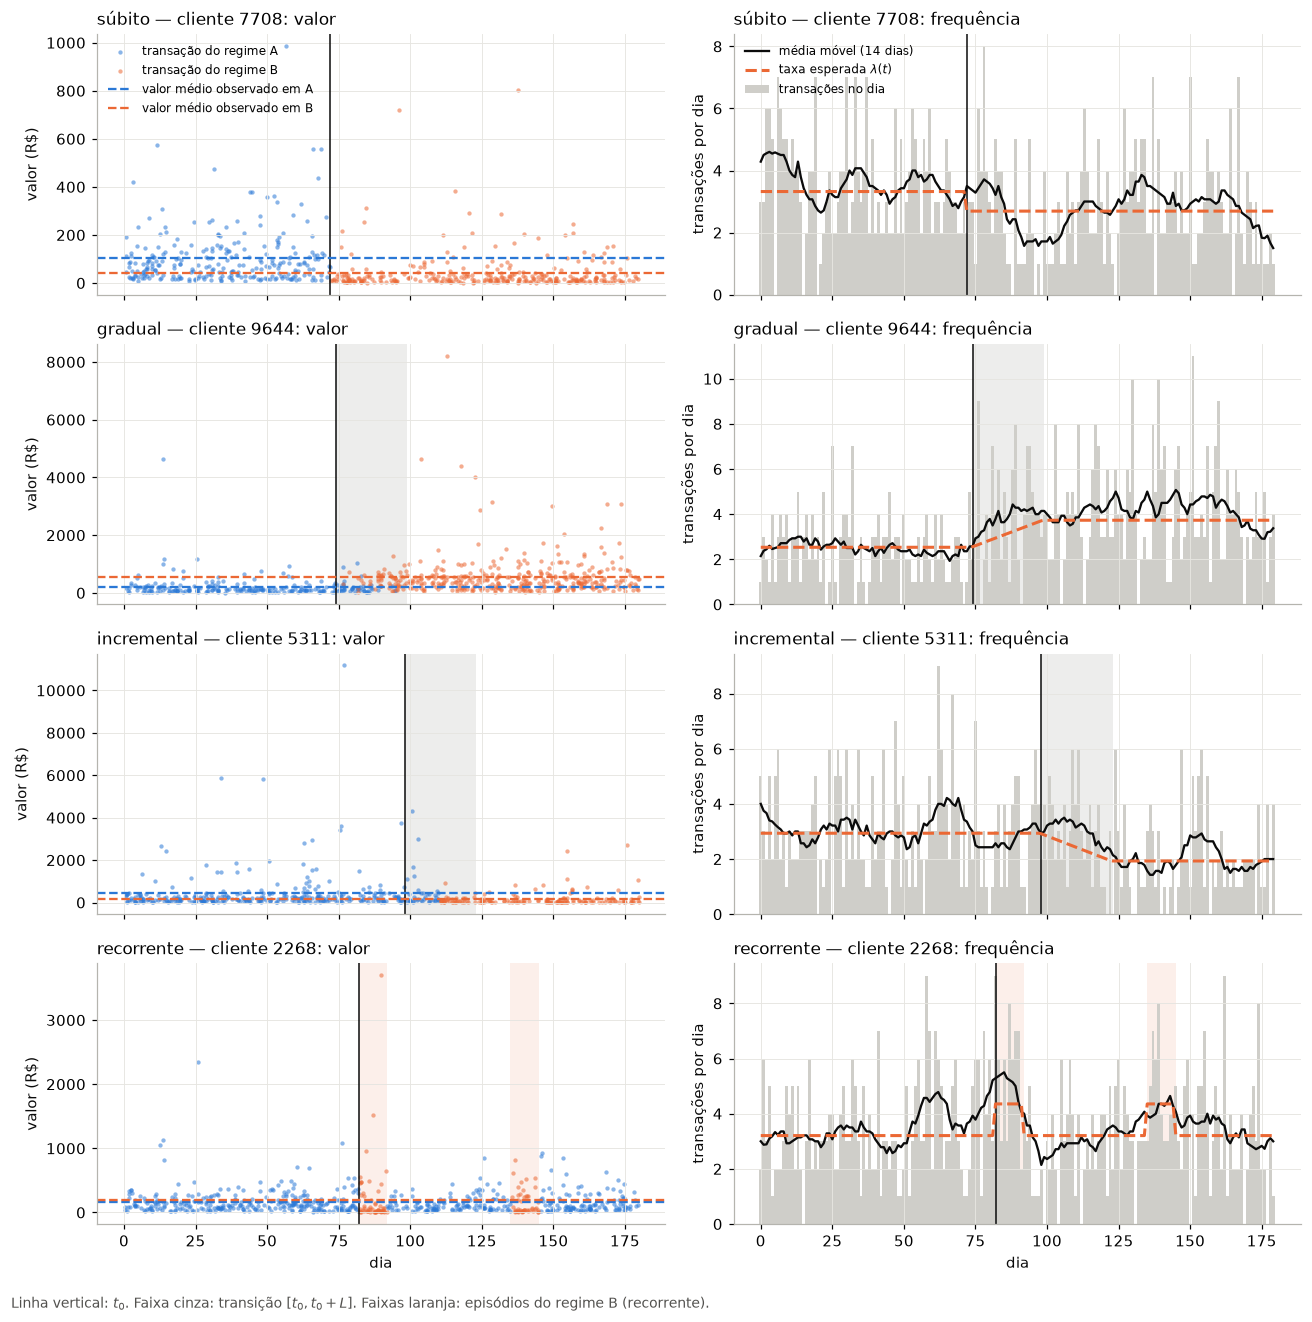

In [4]:
days = np.arange(NB_DAYS)
fig, axes = plt.subplots(4, 2, figsize=(12, 12), sharex=True)

for (kind, row), (ax_amount, ax_count) in zip(examples.items(), axes):
    own = legit[legit.CUSTOMER_ID == row.CUSTOMER_ID]
    w = regime_weight(as_drift(row), days + 0.5)

    # Marks: t0 and the transition (gradual, incremental) or the B episodes (recurrent)
    for ax in (ax_amount, ax_count):
        if kind == "recurrent":
            active = w > 0
            starts = days[active & ~np.r_[False, active[:-1]]]
            ends = days[active & ~np.r_[active[1:], False]] + 1
            for s, e in zip(starts, ends):
                ax.axvspan(s, e, color=COLOR_B, alpha=0.10, lw=0)
        elif kind in ("gradual", "incremental"):
            ax.axvspan(row.GT_DRIFT_T0, row.GT_DRIFT_T0 + row.GT_DRIFT_L, color=MUTED, alpha=0.15, lw=0)
        ax.axvline(row.GT_DRIFT_T0, color=INK, lw=1.0, ls="-")

    for regime, color in (("A", COLOR_A), ("B", COLOR_B)):
        part = own[own.GT_REGIME == regime]
        ax_amount.scatter(part.TX_TIME_SECONDS / 86400, part.TX_AMOUNT, s=8, color=color,
                          alpha=0.55, lw=0, label=f"transação do regime {regime}")
    for regime, color in (("A", COLOR_A), ("B", COLOR_B)):
        mean = own.loc[own.GT_REGIME == regime, "TX_AMOUNT"].mean()
        ax_amount.axhline(mean, color=color, lw=1.5, ls="--", label=f"valor médio observado em {regime}")
    ax_amount.set_ylabel("valor (R$)")
    ax_amount.set_title(f"{TYPE_NAMES[kind]} — cliente {row.CUSTOMER_ID}: valor", loc="left", fontsize=11)

    per_day = own.groupby("TX_TIME_DAYS").size().reindex(days, fill_value=0)
    expected = (1 - w) * row.mean_nb_tx_per_day + w * row.GT_B_mean_nb_tx_per_day
    ax_count.bar(days, per_day, width=1.0, color="#cfcec9", lw=0, label="transações no dia")
    ax_count.plot(days, per_day.rolling(14, center=True, min_periods=1).mean(), color=INK, lw=1.5,
                  label="média móvel (14 dias)")
    ax_count.plot(days, expected, color=COLOR_B, lw=2, ls="--", label=r"taxa esperada $\lambda(t)$")
    ax_count.set_ylabel("transações por dia")
    ax_count.set_title(f"{TYPE_NAMES[kind]} — cliente {row.CUSTOMER_ID}: frequência", loc="left", fontsize=11)

for ax in axes[-1]:
    ax.set_xlabel("dia")
axes[0, 0].legend(loc="upper left", fontsize=8, frameon=False)
axes[0, 1].legend(loc="upper left", fontsize=8, frameon=False)
fig.text(0.01, 0.005, "Linha vertical: $t_0$. Faixa cinza: transição $[t_0, t_0+L]$. "
         "Faixas laranja: episódios do regime B (recorrente).", fontsize=9, color="#52514e")
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(FIG_DIR / "drift_exemplos_clientes.pdf", bbox_inches="tight")
plt.show()

## Fração em B ao longo do tempo

Peso médio do regime B, $\bar w(t)$, entre os clientes de cada tipo, e entre todos os
clientes (inclusive os sem *drift*). Para os tipos súbito e recorrente, $w \in \{0, 1\}$
e $\bar w(t)$ é a fração de clientes em B.

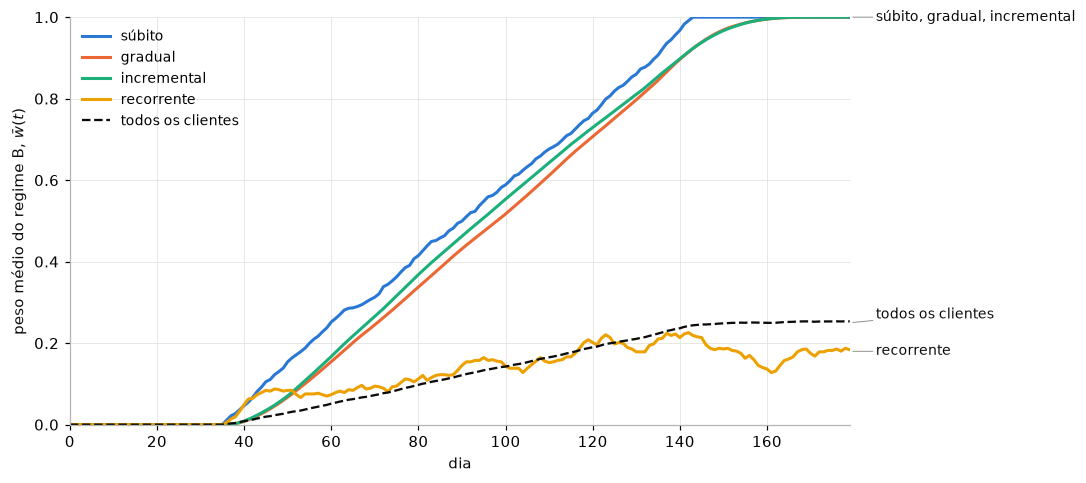

In [5]:
weights = np.vstack([regime_weight(as_drift(row), days + 0.5) for _, row in customers.iterrows()])
kinds = customers.GT_DRIFT_TYPE.to_numpy()

fig, ax = plt.subplots(figsize=(10, 4.5))
ends = {}
for kind, color in TYPE_COLORS.items():
    share = weights[kinds == kind].mean(axis=0)
    ax.plot(days, share, color=color, lw=2, label=TYPE_NAMES[kind])
    ends.setdefault(round(share[-1], 2), []).append(TYPE_NAMES[kind])
overall = weights.mean(axis=0)
ax.plot(days, overall, color=INK, lw=1.5, ls="--", label="todos os clientes")
ends.setdefault(round(overall[-1], 2), []).append("todos os clientes")
# Direct labels just right of the plot; lines ending at the same value share one label,
# and labels closer than GAP are pushed up so they do not overlap
GAP = 0.09
placed = []
for value, names in sorted(ends.items()):
    y = max([value] + [p + GAP for p in placed if p > value - GAP])
    placed.append(y)
    ax.annotate(", ".join(names), (days[-1], value), xytext=(days[-1] + 6, y), textcoords="data",
                va="center", fontsize=9, color=INK, annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6, shrinkA=0, shrinkB=2))
ax.set_xlim(0, NB_DAYS - 1)
ax.set_ylim(0, 1)
ax.set_xlabel("dia")
ax.set_ylabel(r"peso médio do regime B, $\bar w(t)$")
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "drift_fracao_regime_b.pdf", bbox_inches="tight")
plt.show()

## Quanto o regime B difere de A

Distribuição das mudanças sorteadas para os clientes com *drift*: razão entre os valores
(fator de gasto, com comerciantes) e entre as frequências (escala log) e diferença na
probabilidade de CNP.

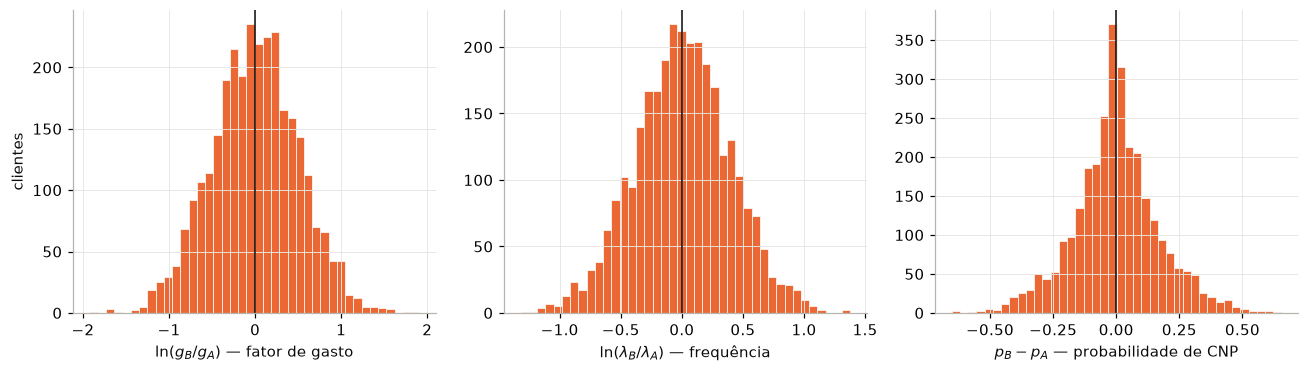

,clientes,mudou_de_cidade,mudanca_media_valor_log
GT_DRIFT_TYPE,,,
gradual,894,43,0.398738
incremental,614,27,0.415483
recurrent,571,23,0.412107
sudden,921,48,0.388065


In [6]:
drifting = customers[customers.GT_DRIFT_TYPE != "none"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
series = [
    (np.log(AMOUNT_RATIO[drifting.index]),
     r"$\ln(g_B / g_A)$ — fator de gasto" if WITH_MERCHANTS else r"$\ln(\mu_B / \mu_A)$ — valor médio"),
    (np.log(drifting.GT_B_mean_nb_tx_per_day / drifting.mean_nb_tx_per_day), r"$\ln(\lambda_B / \lambda_A)$ — frequência"),
    (drifting.GT_B_cnp_prob - drifting.cnp_prob, r"$p_B - p_A$ — probabilidade de CNP"),
]
for ax, (values, label) in zip(axes, series):
    ax.hist(values, bins=40, color=COLOR_B, edgecolor="#fcfcfb", linewidth=0.5)
    ax.axvline(0, color=INK, lw=1)
    ax.set_xlabel(label)
axes[0].set_ylabel("clientes")
fig.tight_layout()
fig.savefig(FIG_DIR / "drift_parametros_regime_b.pdf", bbox_inches="tight")
plt.show()

summary = drifting.assign(
    amount_change=np.abs(np.log(AMOUNT_RATIO[drifting.index])),
).groupby("GT_DRIFT_TYPE").agg(clientes=("CUSTOMER_ID", "size"), mudou_de_cidade=("GT_RELOCATED", "sum"),
                                 mudanca_media_valor_log=("amount_change", "mean"))
summary

## Visão por categoria (com comerciantes)

Com comerciantes (`MerchantConfig`, Fase 4), o regime B também muda a **preferência por
categoria**: $\text{pref}_B = (1 - s)\,\text{pref}_A + s\,\text{nova}$, com
$s \sim \mathcal{U}(0{,}3; 0{,}8)$ e $\text{nova}$ sorteada como a de um cliente novo
(`category_shift_range`), e o gasto passa a ser um fator do cliente, multiplicado pelo
fator de valor do *drift*. Usa os mesmos dados (a configuração final tem comerciantes;
com um *preset* sem comerciantes, o notebook gera os mesmos clientes com eles).

In [7]:
if WITH_MERCHANTS:
    shop_customers, shop_tx = customers, legit
else:
    shop_customers, _, shop_tx = DatasetGenerator(
        **{**PARAMS, "merchants": MerchantConfig()}
    ).generate()
    shop_tx = shop_tx[shop_tx.TX_FRAUD == 0]
CATEGORY_NAMES = list((PARAMS.get("merchants") or MerchantConfig()).names)
pref_a = shop_customers[[f"pref_{n}" for n in CATEGORY_NAMES]].to_numpy()
pref_b = shop_customers[[f"GT_B_pref_{n}" for n in CATEGORY_NAMES]].to_numpy()
drifting_shop = shop_customers.GT_DRIFT_TYPE != "none"
configured_tvd = 0.5 * np.abs(pref_b - pref_a).sum(axis=1)[drifting_shop.to_numpy()]

# Observed category shares of each drifting customer in each regime
shares = (shop_tx[shop_tx.CUSTOMER_ID.isin(shop_customers.CUSTOMER_ID[drifting_shop])]
          .groupby(["CUSTOMER_ID", "GT_REGIME"]).MERCHANT_CATEGORY.value_counts(normalize=True)
          .unstack(fill_value=0.0).reindex(columns=CATEGORY_NAMES, fill_value=0.0))
both = shares.index.get_level_values(0).value_counts()
both = both[both == 2].index
observed_tvd = 0.5 * (shares.xs("B", level=1).loc[both] - shares.xs("A", level=1).loc[both]).abs().sum(axis=1)
print(f"distância de variação total entre as preferências de A e B: média {configured_tvd.mean():.2f} "
      f"(configurada) e {observed_tvd.mean():.2f} (observada, {len(both)} clientes com compras nos dois regimes)")

distância de variação total entre as preferências de A e B: média 0.24 (configurada) e 0.30 (observada, 2980 clientes com compras nos dois regimes)


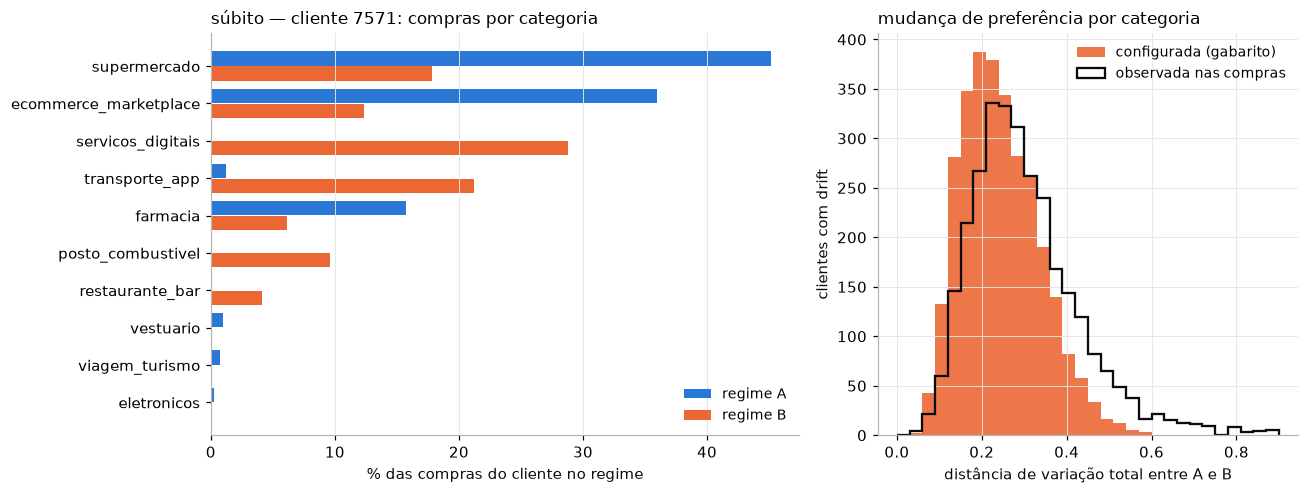

In [8]:
# Example: a frequent sudden customer with a large change of preferences
sudden_ids = shop_customers.index[(shop_customers.GT_DRIFT_TYPE == "sudden")
                                  & (shop_customers.mean_nb_tx_per_day >= 2.5)]
tvd = pd.Series(0.5 * np.abs(pref_b - pref_a).sum(axis=1), index=shop_customers.index)
example = tvd.loc[sudden_ids].idxmax()
example_shares = shares.loc[example].T  # categories x regimes

fig, (ax_example, ax_hist) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
order = example_shares.max(axis=1).sort_values().index
y = np.arange(len(order))
ax_example.barh(y + 0.2, 100 * example_shares.loc[order, "A"], height=0.38, color=COLOR_A, label="regime A")
ax_example.barh(y - 0.2, 100 * example_shares.loc[order, "B"], height=0.38, color=COLOR_B, label="regime B")
ax_example.set_yticks(y, order)
ax_example.set_xlabel("% das compras do cliente no regime")
ax_example.set_title(f"súbito — cliente {example}: compras por categoria", loc="left", fontsize=11)
ax_example.legend(loc="lower right", frameon=False, fontsize=9)
ax_example.grid(axis="y", visible=False)

bins = np.linspace(0, 0.9, 31)
ax_hist.hist(configured_tvd, bins=bins, color=COLOR_B, alpha=0.9, label="configurada (gabarito)")
ax_hist.hist(observed_tvd, bins=bins, histtype="step", color=INK, lw=1.5, label="observada nas compras")
ax_hist.set_xlabel("distância de variação total entre A e B")
ax_hist.set_ylabel("clientes com drift")
ax_hist.legend(loc="upper right", frameon=False, fontsize=9)
ax_hist.set_title("mudança de preferência por categoria", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "drift_categorias.pdf", bbox_inches="tight")
plt.show()